# Exploratory Data Analysis (EDA)

## 1. Introduction

The first step in building a fraud detection system is to understand the data we are working with. Before making decisions about preprocessing or model selection, we need to examine the structure of the dataset, understand how fraudulent transactions differ from legitimate ones, and identify issues that could affect model performance.

This project uses the **Credit Card Fraud Detection dataset from ULB**, which contains transaction records with anonymized features. The dataset includes `Time`, `Amount`, 28 PCA-transformed features (`V1`–`V28`), and a target variable, `Class`, indicating whether a transaction is legitimate or fraudulent.

One of the main challenges is the severe imbalance between the two classes. Fraudulent transactions make up only a small proportion of the dataset, so a model could achieve high accuracy while failing to detect most fraudulent transactions. Another challenge is that the PCA-transformed features do not have directly interpretable business meanings. Our analysis will therefore focus on their statistical properties and their ability to distinguish between the two classes, without assigning meanings that the data does not support.

The purpose of this EDA is to understand the dataset, identify relevant patterns, assess potential data quality and modeling issues, and use the findings to guide the preprocessing and modeling stages.

## 2. Objectives

The analysis will focus on the following objectives:

- Examine the structure and quality of the dataset.
- Understand the distribution of legitimate and fraudulent transactions.
- Investigate the distributions of individual features.
- Compare fraudulent and legitimate transactions to identify potentially useful patterns.
- Examine relationships among features and their association with the target.
- Identify potential data leakage, outliers, and other modeling risks.
- Translate the findings into practical decisions for preprocessing, model development, and evaluation.

## 3. EDA Workflow

The analysis is divided into seven phases. Each phase addresses a specific set of questions and contributes to our understanding of the data.

### Phase 1: Data Understanding and Structural Validation

Establish what the dataset contains and assess its basic integrity. This includes examining its dimensions, feature types, missing values, duplicate records, target labels, and summary statistics.

### Phase 2: Target Analysis and Class Imbalance

Examine the distribution of legitimate and fraudulent transactions. Quantify the degree of imbalance and establish why accuracy alone is not an appropriate measure of model performance.

### Phase 3: Univariate Feature Analysis

Study the distribution of individual features, including `Time`, `Amount`, and the PCA components. Examine their ranges, spread, skewness, and unusual values to identify characteristics that may be relevant to preprocessing or modeling.

### Phase 4: Comparative Analysis — Fraud vs. Legitimate Transactions

Compare the two classes across selected features. The aim is to identify distributional differences that may help distinguish fraudulent transactions from legitimate ones.

### Phase 5: Relationships and Multivariate Analysis

Investigate relationships among features using correlation analysis and other relevant techniques. Examine whether individual features or combinations of features may provide useful information for distinguishing the two classes.

### Phase 6: Data Leakage, Outliers, and Modeling Risks

Review potential problems that could compromise model development or evaluation. This includes examining unusual observations, considering the implications of the dataset's time structure, and identifying preprocessing operations that must be restricted to the training data.

### Phase 7: EDA Conclusions and Modeling Recommendations

Summarize the main findings and explain how they affect the next stage of the project. The conclusions will guide preprocessing, imbalance-handling experiments, evaluation metric selection, and the subsequent modeling workflow.

## 4. Approach to Analysis

Each phase will follow the same process:

1. **Question:** Define what we need to understand.
2. **Analysis:** Select appropriate statistics, tables, or visualizations.
3. **Interpretation:** Explain what the results show and what they do not establish.
4. **Decision:** Document any implications for the next stage of the project.

This approach keeps the analysis focused on answering relevant questions rather than producing plots without a clear purpose.

## 5. Expected Outcome

By the end of the EDA, we should have a clear understanding of the dataset's structure, class imbalance, feature distributions, and potential modeling risks. We should also have documented findings that justify our preprocessing and evaluation decisions.

EDA will not determine the final model by itself. Instead, it will provide the evidence needed to design sound experiments and evaluate models fairly in the next stage of the fraud detection project.

## Phase 1: Data Understanding and Structural Validation

The first phase focuses on understanding the dataset and checking its basic quality before proceeding with further analysis.

### Objectives

- Understand the dataset and its prediction objective.
- Examine the number of rows, columns, and data types.
- Check for missing values, duplicate records, and invalid values.
- Identify the target variable and distinguish it from the input features.
- Review the feature ranges and summary statistics.
- Document the limitations of the anonymized PCA features.

### Expected Outcome

By the end of this phase, the dataset's structure, quality, and feature characteristics should be clearly understood. Any issues requiring further investigation should be documented before moving to the next phase.

In [1]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
pd.set_option('display.max_columns', None)

In [2]:
# load the dataset and display the first 5 rows
data = pd.read_csv('../data/raw/creditcard.csv')
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# investigate data dimension
data.shape

(284807, 31)

In [4]:
data.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

### Dataset Structure

The dataset contains 284,807 transactions and 31 columns. These consist of 30 input features and one target variable, `Class`. The input features include `Time`, 28 PCA-transformed variables (`V1`–`V28`), and `Amount`.

The column inspection confirms that all expected columns are present. The next step is to examine the data types and check for potential data quality issues before proceeding with further analysis.

In [5]:
# inspect data types
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

### Data Types and Completeness

The dataset contains 31 columns, of which 30 are stored as `float64` and one as `int64`. The `Class` column, which represents the target variable, is stored as an integer, while all input features are represented as floating-point numbers.

The `info()` output shows 284,807 non-null values in every column, indicating that there are no missing values reported by pandas. 

Based on this inspection, the column data types appear consistent with their intended use. However, further checks are needed to assess duplicate records, numerical validity, and the integrity of the target labels.

In [6]:
# invesigate duplicated rows
data.duplicated().sum()

np.int64(1081)

In [7]:
# invesitigate if "Class" column contains 0 and 1 values only
data['Class'].unique()

array([0, 1])

In [8]:
# invesigate Numerical validity of the data

data.describe().T

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995


### Initial Data Quality and Statistical Findings

The target variable contains only the expected labels, 0 and 1, and the earlier structural inspection reported no missing values. However, the duplicate check identified 1,081 repeated rows, which require further investigation before any decision is made about removing them.

The descriptive statistics show that the PCA-transformed features have means generally close to zero, while their ranges and standard deviations vary. The `Amount` feature has a mean of approximately 88.35 and a median of 22, suggesting that its distribution may be right-skewed.

The mean of the binary `Class` variable is approximately 0.00173, indicating that fraudulent transactions represent a very small proportion of the dataset. This will be investigated further during the class imbalance analysis.

At this stage, no records will be removed based solely on these observations. Additional checks are needed to understand the duplicate records and validate the numerical values.

In [9]:
# invesigate the duplicates

data[data.duplicated()]['Class'].value_counts()

Class
0    1062
1      19
Name: count, dtype: int64

In [10]:
data[data.duplicated()]['Class'].value_counts(normalize=True)

Class
0    0.982424
1    0.017576
Name: proportion, dtype: float64

### Decision: Handling Duplicate Records

The dataset contains 1,081 rows flagged as exact duplicates, representing approximately 0.38% of the original 284,807 observations. Of these, 1,062 are labeled as legitimate transactions and 19 as fraudulent transactions.

Exact duplicate rows will be removed from the working dataset to reduce the repeated influence of identical observations during model development. The original dataset will remain unchanged so that the cleaning process can be reproduced and reviewed.

This decision is based on identical recorded feature values, not on proof that the observations represent the same real-world transaction. After removal, the dataset dimensions and class distribution will be checked to confirm the effect of the operation.

In [11]:
# drop duplicates

df = data.copy()
df = df.drop_duplicates()

In [12]:
df.shape

(283726, 31)

In [13]:
# check for infinite values

np.isinf(df).sum().sum()

np.int64(0)

In [14]:
df.nunique()

Time      124592
V1        275663
V2        275663
V3        275663
V4        275663
V5        275663
V6        275663
V7        275663
V8        275663
V9        275663
V10       275663
V11       275663
V12       275663
V13       275663
V14       275663
V15       275663
V16       275663
V17       275663
V18       275663
V19       275663
V20       275663
V21       275663
V22       275663
V23       275663
V24       275663
V25       275663
V26       275663
V27       275663
V28       275663
Amount     32767
Class          2
dtype: int64

### Numerical Validity Checks

The numerical validity checks found no infinite values in the dataset. The unique-value counts also indicate that no constant columns are present, as every feature has more than one distinct value and the target variable contains two classes.

These results suggest that the dataset does not require any immediate corrections for infinite values or constant features. However, the duplicate-removal step still needs to be verified before the data-quality assessment can be considered complete.

In [16]:
# Class counts

df['Class'].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [17]:
# class percentage and imbalance ratio
class_counts = df['Class'].value_counts()
class_percentages = class_counts / len(df) * 100
imbalance_ratio = class_counts.iloc[0] / class_counts.iloc[1]

print("Class Counts:\n", class_counts)
print("\nClass Percentages:\n", class_percentages)
print("\nImbalance Ratio:\n", imbalance_ratio)

Class Counts:
 Class
0    283253
1       473
Name: count, dtype: int64

Class Percentages:
 Class
0    99.83329
1     0.16671
Name: count, dtype: float64

Imbalance Ratio:
 598.8435517970402


/tmp/ipykernel_4758/3278039414.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label, y=class_count.values, palette='viridis')


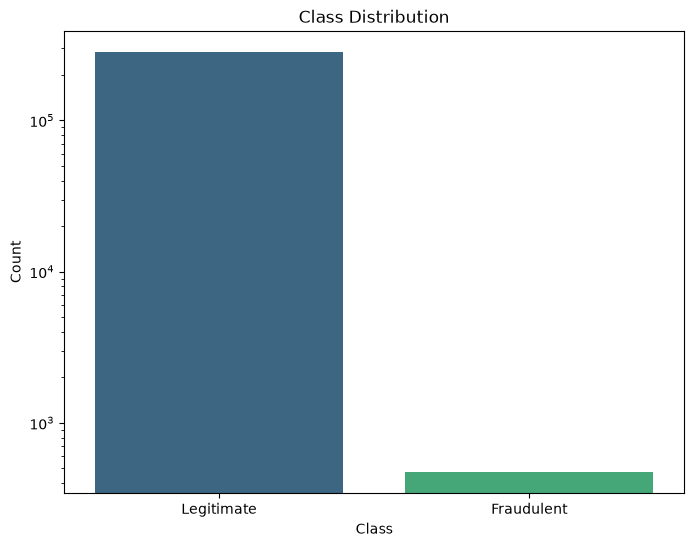

In [20]:
# plot the class distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
class_count = df['Class'].value_counts()
label = ['Legitimate', 'Fraudulent']
sns.barplot(x=label, y=class_count.values, palette='viridis')
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.yscale('log')  # Use logarithmic scale for better visualization
plt.show()

### Class Distribution and Imbalance

After removing duplicate rows, the dataset contains 283,726 transactions. Of these, 283,253 are legitimate and 473 are fraudulent.

Legitimate transactions account for approximately 99.83% of the dataset, while fraudulent transactions represent only 0.17%. This corresponds to an imbalance ratio of approximately 599 legitimate transactions for every fraudulent transaction.

The class distribution plot highlights the large difference between the two classes. A logarithmic scale is used to make the smaller fraud class more visible alongside the much larger legitimate class.

This imbalance has important implications for model evaluation. A classifier that predicts every transaction as legitimate would achieve approximately 99.83% accuracy while failing to identify any fraudulent transactions. Accuracy alone would therefore give a misleading impression of model performance.

The results indicate that fraud detection performance must be assessed using metrics that account for the minority class, particularly precision, recall, F1-score, and precision–recall AUC.

In [26]:
# Time analysis

# minimum and maximum time values
print("Minimum Time Value:", df['Time'].min()//1440, "days")  # Convert to days
print("Maximum Time Value:", df['Time'].max()//1440, "days")  # Convert to days

Minimum Time Value: 0.0 days
Maximum Time Value: 119.0 days


In [29]:
# check the distribution of the "Time" column
df['Time'].describe()

count    283726.000000
mean      94811.077600
std       47481.047891
min           0.000000
25%       54204.750000
50%       84692.500000
75%      139298.000000
max      172792.000000
Name: Time, dtype: float64

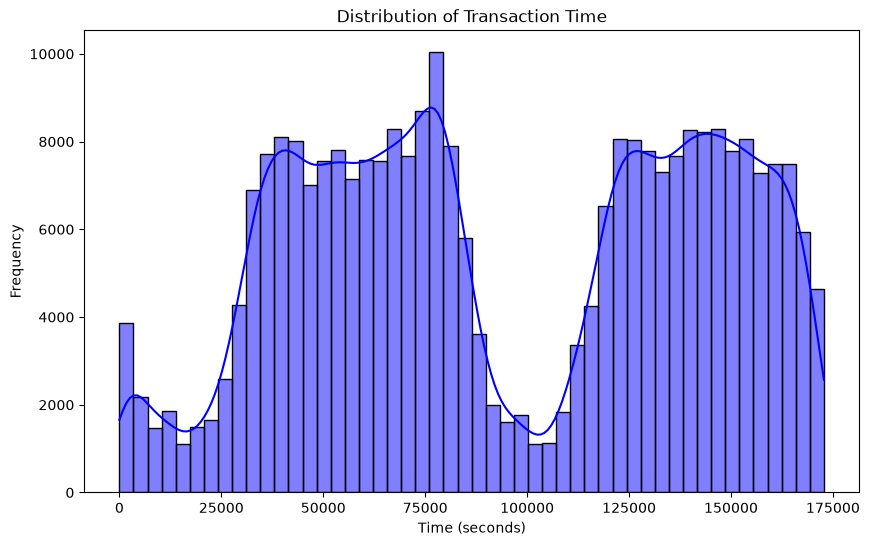

In [32]:
# plot time distribution
plt.figure(figsize=(10, 6))
sns.histplot(df['Time'], bins=50, kde=True, color='blue')
plt.title('Distribution of Transaction Time')
plt.xlabel('Time (seconds)')
plt.ylabel('Frequency') 
plt.show()

### Distribution of Transaction Time

The histogram of `Time` shows a bimodal-looking distribution, with two broad concentrations of transactions separated by a region of lower frequency. The first concentration occurs around 30,000–85,000 seconds, while the second occurs around 120,000–165,000 seconds.

This indicates that transactions are not distributed uniformly across the recorded observation period. However, the histogram alone does not explain the cause of these concentrations or establish distinct transaction behaviors.

The mean is greater than the median, suggesting some right-skewness, although the distribution has a more complex shape than a simple unimodal distribution. Further analysis would be required to understand the underlying temporal pattern.

In [34]:
# Amount Analysis

df['Amount'].describe()

count    283726.000000
mean         88.472687
std         250.399437
min           0.000000
25%           5.600000
50%          22.000000
75%          77.510000
max       25691.160000
Name: Amount, dtype: float64

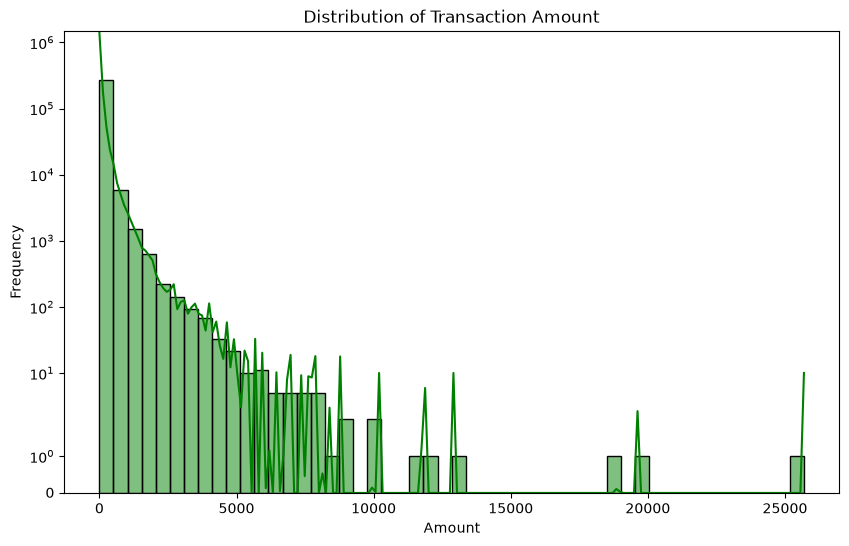

In [38]:
# check distribution of the "Amount" column
plt.figure(figsize=(10, 6))
sns.histplot(df['Amount'], bins=50, kde=True, color='green')
plt.title('Distribution of Transaction Amount')
plt.xlabel('Amount')
plt.ylabel('Frequency') 
plt.yscale('symlog')  # Use logarithmic scale for better visualization
plt.show()

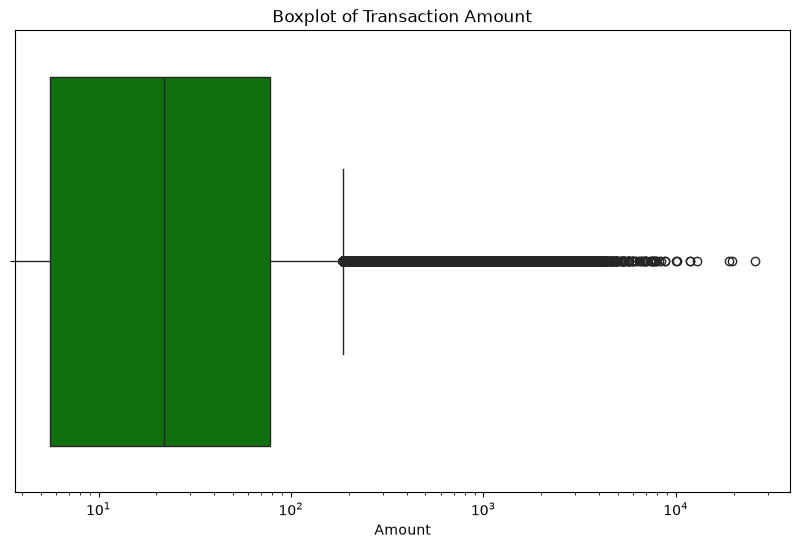

In [42]:
# check for outliers in the "Amount" column using boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Amount'], color='green')
plt.title('Boxplot of Transaction Amount')
plt.xlabel('Amount')
plt.xscale('log')  # Use logarithmic scale for better visualization
plt.show()

### Distribution of Transaction Amount

The histogram shows that transaction amounts are strongly right-skewed. Most observations are concentrated at relatively low amounts, while a small number of transactions extend into the upper tail. The mean of approximately 88.47 is substantially greater than the median of 22.00, supporting this observation.

The boxplot also identifies numerous potential upper-tail outliers under the IQR rule. These values are not automatically errors, particularly in a fraud detection problem where unusual transaction amounts may contain useful information.

No observations will be removed based solely on their position in the distribution. The skewness, wide numerical range, and potential outliers will be considered when deciding on preprocessing methods. Their relationship with the target class will be examined during the comparative analysis phase.

In [43]:
# PCA feature analysis

pca_columns = [col for col in df.columns if col.startswith('V')]

df[pca_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
V1,283726.0,0.005917,1.948026,-56.407510,-0.915951,0.020384,1.316068,2.454930
V2,283726.0,-0.004135,1.646703,-72.715728,-0.600321,0.063949,0.800283,22.057729
V3,283726.0,0.001613,1.508682,-48.325589,-0.889682,0.179963,1.026960,9.382558
V4,283726.0,-0.002966,1.414184,-5.683171,-0.850134,-0.022248,0.739647,16.875344
V5,283726.0,0.001828,1.377008,-113.743307,-0.689830,-0.053468,0.612218,34.801666
V6,283726.0,-0.001139,1.331931,-26.160506,-0.769031,-0.275168,0.396792,73.301626
V7,283726.0,0.001801,1.227664,-43.557242,-0.552509,0.040859,0.570474,120.589494
V8,283726.0,-0.000854,1.179054,-73.216718,-0.208828,0.021898,0.325704,20.007208
V9,283726.0,-0.001596,1.095492,-13.434066,-0.644221,-0.052596,0.595977,15.594995
V10,283726.0,-0.001441,1.076407,-24.588262,-0.535578,-0.093237,0.453619,23.745136


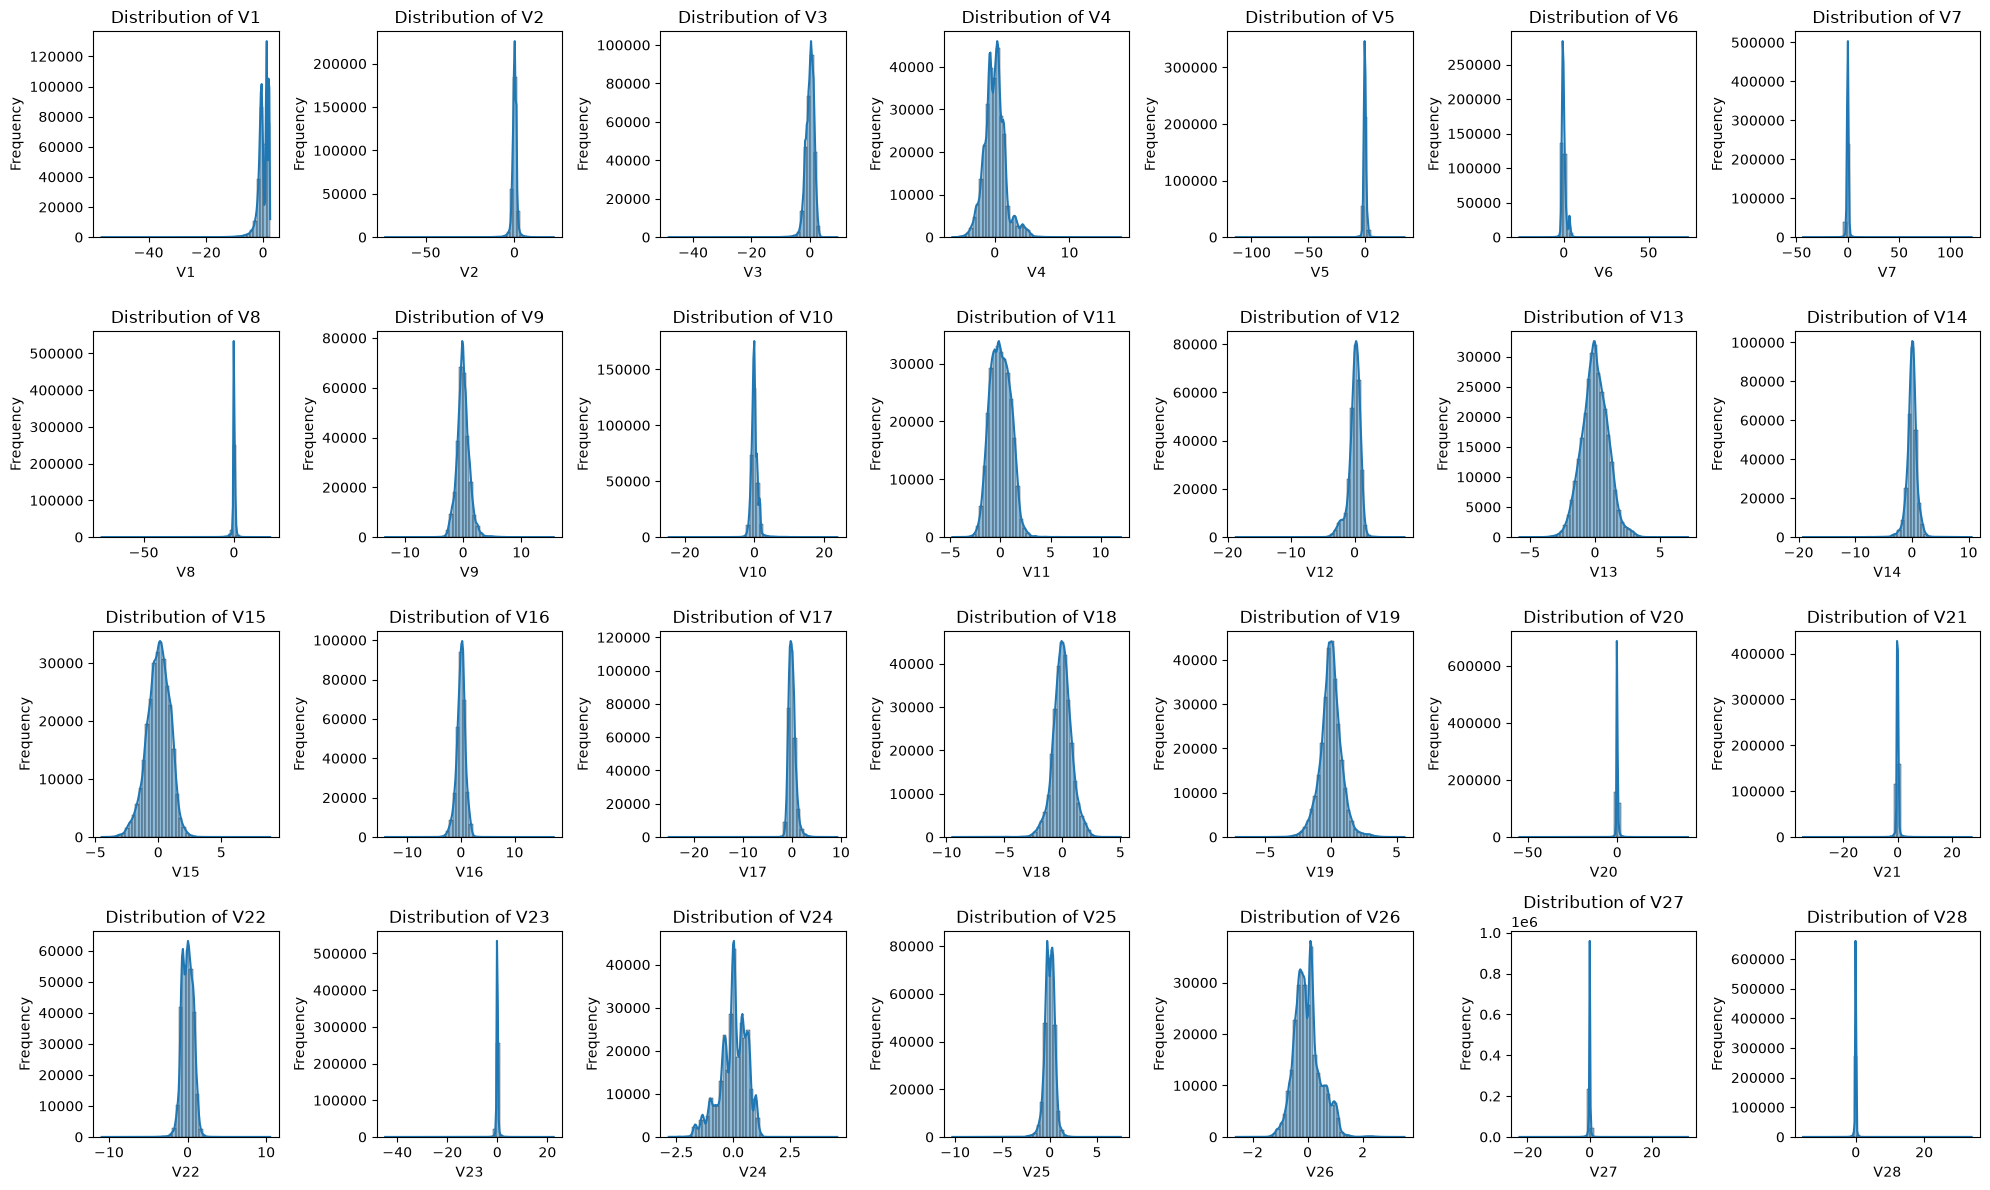

In [45]:
# distribution of PCA features

fig, axes = plt.subplots(nrows=4, ncols=7, figsize=(20, 12))
axes = axes.flatten()

for axe, col in zip(axes, pca_columns):
    sns.histplot(df[col], bins=50, kde=True, ax=axe)
    axe.set_title(f'Distribution of {col}')
    axe.set_xlabel(col)
    axe.set_ylabel('Frequency')

plt.tight_layout()
plt.show()
     

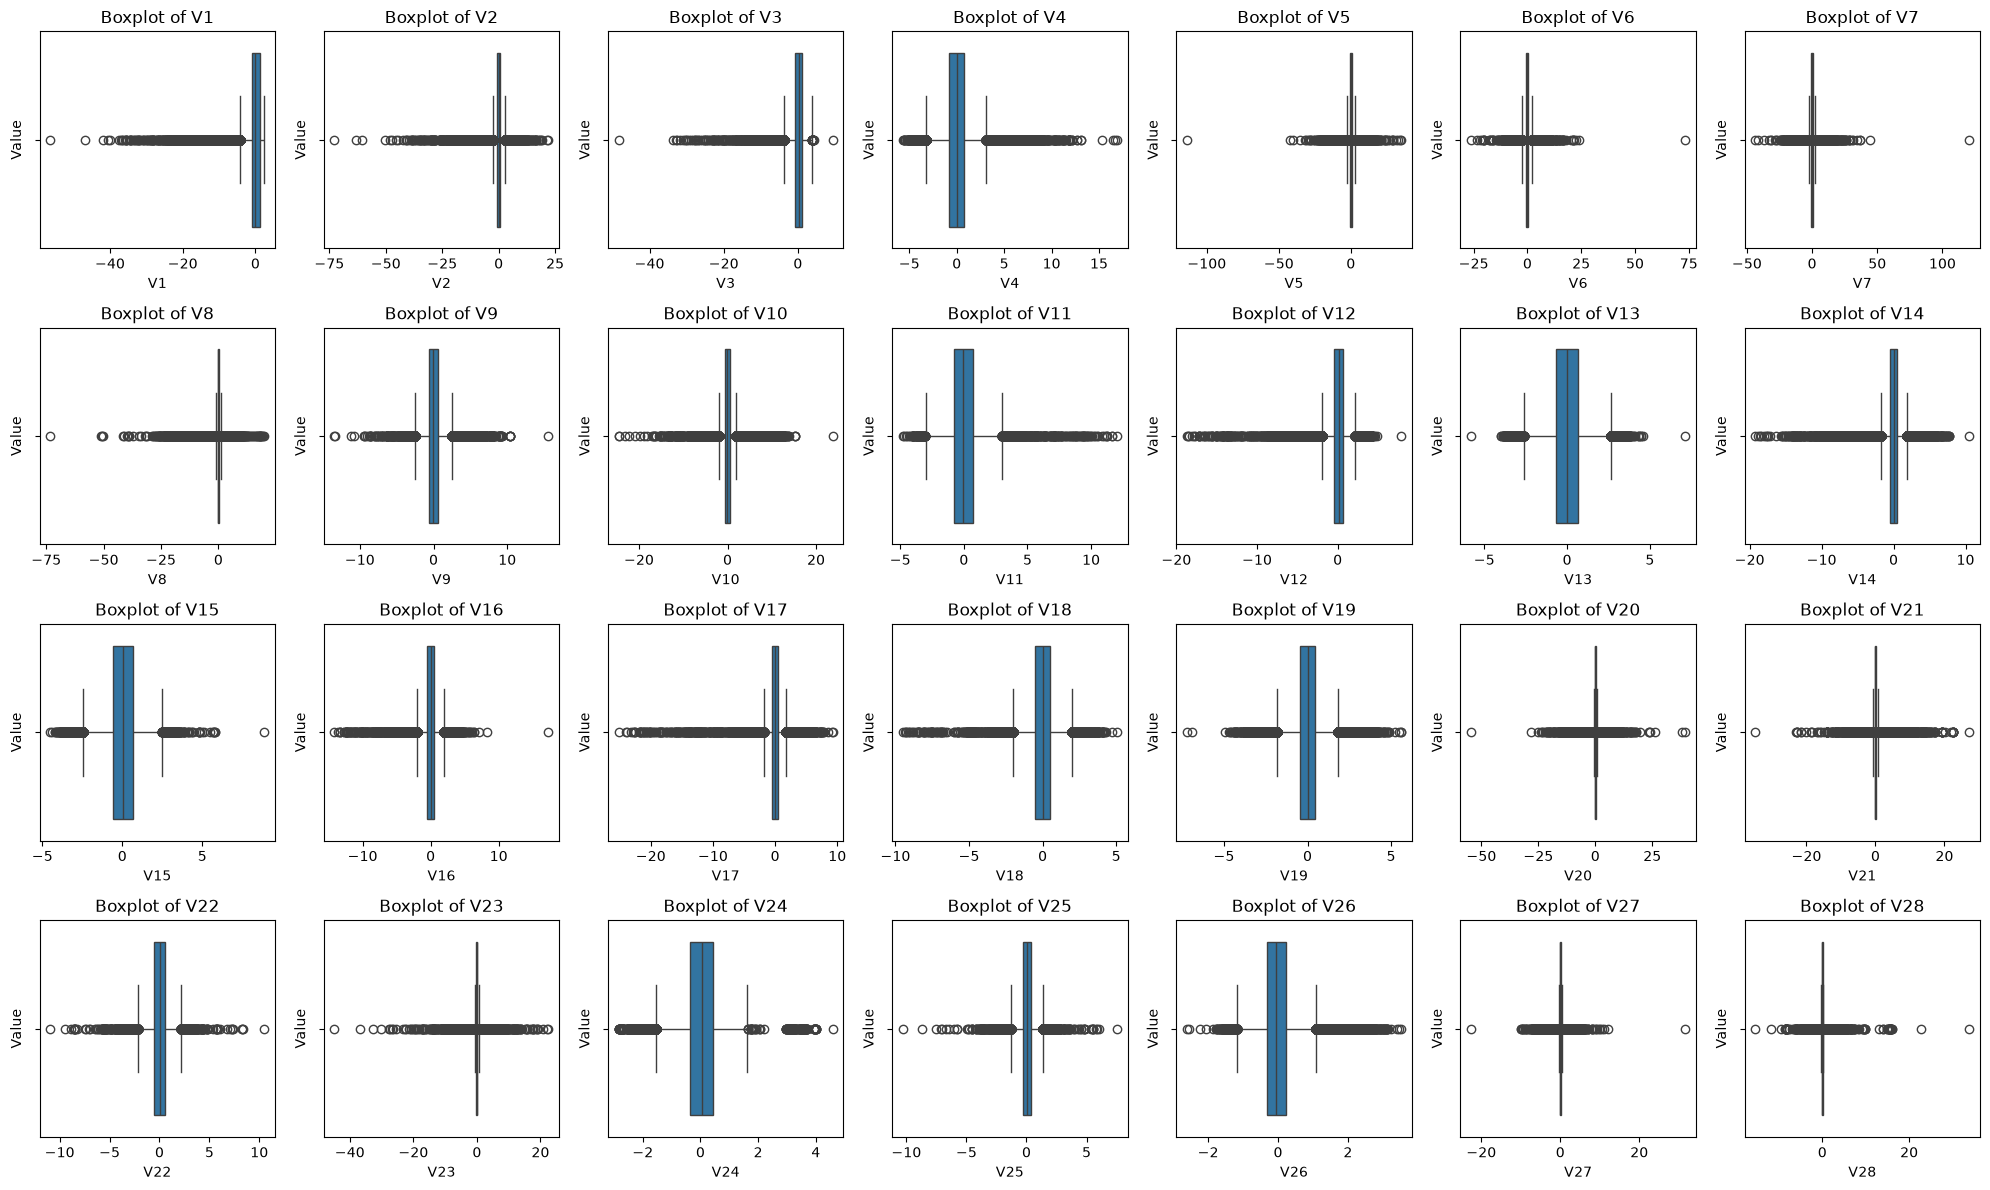

In [46]:
# check pca feature outliers using boxplots

fig, axes = plt.subplots(nrows=4, ncols=7, figsize=(20, 12))
axes = axes.flatten()   

for axe, col in zip(axes, pca_columns):
    sns.boxplot(x=df[col], ax=axe)
    axe.set_title(f'Boxplot of {col}')
    axe.set_xlabel(col)
    axe.set_ylabel('Value')

plt.tight_layout()
plt.show()

### Distribution of PCA Features

The histograms of `V1`–`V28` show that most features are concentrated around zero, although their distribution shapes and spreads vary. Several components exhibit long tails and extreme values, while others have narrower central distributions.

The boxplots identify potential outliers across multiple components. These observations are not automatically invalid and will not be removed solely because they fall outside the IQR-based whiskers. Their predictive usefulness will be investigated during later analysis and modeling.

The descriptive statistics also show that the PCA components have different standard deviations. Although their means are generally close to zero, their variances are not identical. Since the original business meanings of these components are unavailable, the analysis is limited to their statistical properties and potential predictive value.

In [55]:
# Transaction Amount by class distribution

df.groupby('Class')['Amount'].describe()


,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,88.413575,250.379023,0.0,5.67,22.00,77.46,25691.16
1,473.0,123.871860,260.211041,0.0,1.00,9.82,105.89,2125.87


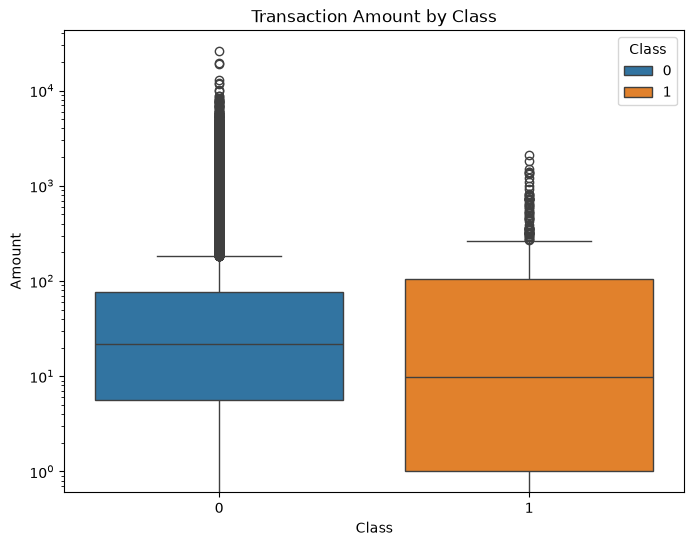

In [61]:
# plot the Amount distribution by class

plt.figure(figsize=(8, 6))
sns.boxplot(x='Class', y='Amount', data=df, hue='Class')
plt.title('Transaction Amount by Class')
plt.xlabel('Class')
plt.ylabel('Amount')    
plt.yscale('log')  # Use logarithmic scale for better visualization
plt.show()

### Transaction Amount by Class

The transaction amount distributions differ between legitimate and fraudulent transactions. Fraudulent transactions have a lower median amount of 9.82 compared with 22.00 for legitimate transactions, while their mean amount is higher at 123.87 compared with 88.41.

This difference between the mean and median suggests that a relatively small number of larger fraud transactions may influence the average. The interquartile range is also wider for fraud transactions, indicating a greater absolute spread across the middle 50% of their observed amounts.

Both classes contain potential upper-tail outliers. These observations will be retained because unusually large transaction amounts are not necessarily invalid. The distributions overlap, so transaction amount alone cannot be assumed to reliably distinguish fraudulent transactions from legitimate ones.

In [62]:
# Time distribution by class

df.groupby('Class')['Time'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,283253.0,94835.058093,47475.550607,0.0,54233.0,84711.0,139308.0,172792.0
1,473.0,80450.513742,48636.179973,406.0,41203.0,73408.0,129095.0,170348.0


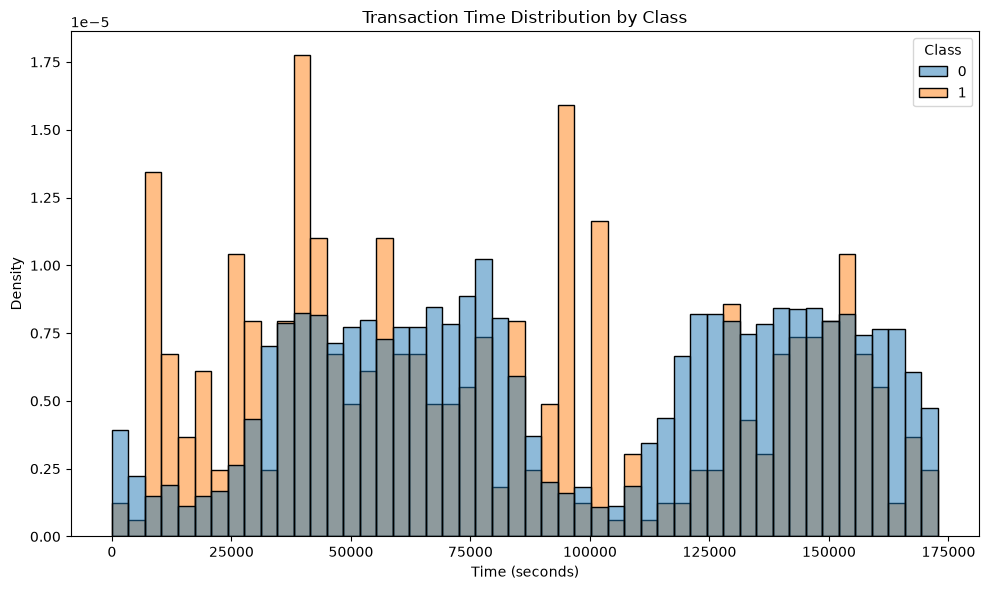

In [71]:

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x='Time',
    hue='Class',
    bins=50,
    element='bars',
    alpha=0.5,
    common_norm=False,
    stat='density'
)

plt.title('Transaction Time Distribution by Class')
plt.xlabel('Time (seconds)')
plt.ylabel('Density')
plt.tight_layout()
plt.show()


### Transaction Time Distribution by Class

The overlaid histograms show differences in the temporal distributions of legitimate and fraudulent transactions. The legitimate class retains the two broad concentrations observed during the univariate analysis, while the fraud distribution appears more irregular, with several local peaks and dips.

There is considerable overlap between the two distributions, and the fraud histogram is less smooth, partly because the fraudulent class contains far fewer observations. The observed peaks should therefore be treated as exploratory patterns rather than evidence of distinct fraud periods.

This comparison does not establish whether transaction time is a useful predictor of fraud. Further evaluation during model development will be needed to determine its predictive value.